<div class="alert alert-block alert-success" style="font-family: Times New Roman">
    <h4><strong>Laboratory Activity 7: Image Classification Using Pre-trained Models</strong></h4>

<p style="font-family:Times New Roman; text-align:justify; font-size:15px">
    <b>Instruction:</b> Find or build an image classification dataset, curate it, write a custom PyTorch
    <tt>Dataset</tt> class and <tt>DataLoader</tt> objects for it, then run inference with up to five
    pre-trained models from <tt>torchvision.models</tt>. Compare the models using accuracy, precision, recall
    and F1-score, present the comparison with tables and visualizations, and close with a short analysis of
    why the models performed differently.
</p>
</div>

<p style="font-family:Times New Roman; text-align:justify; font-size:15px">
The dataset for this lab is <b>Cats vs. Dogs</b>. It is a good fit for models pre-trained on ImageNet because
ImageNet already contains both animals: classes 281&ndash;285 are domestic cats (tabby, tiger cat, Persian,
Siamese, Egyptian cat) and classes 151&ndash;268 are 118 individual dog breeds. That means no training or
fine-tuning is needed &mdash; each model predicts one of its 1,000 ImageNet classes, and that prediction is
mapped back to <tt>cat</tt>, <tt>dog</tt>, or <tt>other</tt> (anything that is neither, e.g. "lynx",
"teddy bear", "wolf"). An <tt>other</tt> prediction always counts as a mistake, so the task is a
little harder than a plain two-way choice.
<br><br>
The five models compared are <b>ResNet-18</b>, <b>ResNet-50</b>, <b>MobileNetV2</b>, <b>EfficientNet-B0</b>
and <b>ViT-B/16</b> (Vision Transformer). They were picked to cover different design ideas: a small and a
large residual CNN, two lightweight mobile-oriented CNNs, and a transformer that has no convolutions after
its first patch-embedding layer.
</p>

<h4 style="font-family: Times New Roman"><strong>1. Imports and Setup</strong></h4>

In [1]:
import os
import random
import shutil
import hashlib
import subprocess
import time
import urllib.request

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision
import torchvision.models as models
import torchvision.transforms as T
from PIL import Image
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, classification_report)
import matplotlib.pyplot as plt


def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__, '| torchvision:', torchvision.__version__)
print('Device:', device)

PyTorch: 2.14.1+cu130 | torchvision: 0.29.1+cu130
Device: cpu


<h4 style="font-family: Times New Roman"><strong>2. Getting the Raw Images</strong></h4>

<p style="font-family:Times New Roman; text-align:justify; font-size:15px">
The images come from a public GitHub mirror of the Kaggle <i>Dogs vs. Cats</i> dataset
(<tt>laxmimerit/dog-cat-full-dataset</tt>), which keeps every photo as a separate JPEG inside
<tt>data/train/{cats,dogs}</tt> and <tt>data/test/{cats,dogs}</tt>. Since the models are only being
evaluated, not trained, just the <tt>test</tt> folder is needed (2,500 cats + 2,500 dogs). A
<i>sparse</i> git checkout downloads that folder only, instead of all 25,000 images.
</p>

In [2]:
RAW_DIR = os.path.join('data', 'dog-cat-full-dataset')
REPO_URL = 'https://github.com/laxmimerit/dog-cat-full-dataset'

if not os.path.exists(os.path.join(RAW_DIR, 'data', 'test')):
    subprocess.run(['git', 'clone', '--depth', '1', '--filter=blob:none', '--sparse', REPO_URL, RAW_DIR], check=True)
    subprocess.run(['git', '-C', RAW_DIR, 'sparse-checkout', 'set', 'data/test'], check=True)

RAW_TEST = os.path.join(RAW_DIR, 'data', 'test')
for folder in sorted(os.listdir(RAW_TEST)):
    print(f"{folder:5}: {len(os.listdir(os.path.join(RAW_TEST, folder)))} files")

cats : 2500 files
dogs : 2500 files


<h4 style="font-family: Times New Roman"><strong>3. Curating and Organizing the Dataset</strong></h4>

<p style="font-family:Times New Roman; text-align:justify; font-size:15px">
Raw scraped images are messy, so before anything touches a model each file goes through four checks:
<ol style="font-family:Times New Roman; text-align:justify; font-size:15px">
  <li><b>It opens</b> &mdash; <tt>PIL.Image.verify()</tt> catches truncated or corrupted JPEGs.</li>
  <li><b>It is big enough</b> &mdash; anything under 64&nbsp;px on its shorter side would be upscaled almost
      4&times; to reach 224&nbsp;px, so it is dropped.</li>
  <li><b>It is not a duplicate</b> &mdash; the MD5 hash of the file bytes is used to remove exact copies.</li>
  <li><b>It is converted to RGB</b> later in the <tt>Dataset</tt>, so grayscale or CMYK files do not break the
      3-channel models.</li>
</ol>
From the clean images, <b>500 cats and 500 dogs</b> are sampled with a fixed seed so the classes are perfectly
balanced and the run is reproducible. They are copied into the standard one-folder-per-class layout,
<tt>data/lab7_cats_dogs/{cat,dog}/</tt>, and a <tt>labels.csv</tt> file records each image's path and label.
</p>

In [3]:
CLASSES = ['cat', 'dog']
SRC_FOLDERS = {'cat': 'cats', 'dog': 'dogs'}
N_PER_CLASS = 500
MIN_SIDE = 64
DATA_DIR = os.path.join('data', 'lab7_cats_dogs')


def is_clean(path):
    try:
        with Image.open(path) as im:
            im.verify()
        with Image.open(path) as im:
            return min(im.size) >= MIN_SIDE
    except Exception:
        return False


def file_md5(path):
    with open(path, 'rb') as f:
        return hashlib.md5(f.read()).hexdigest()


rng = random.Random(42)
rows, log = [], []
for label, cls in enumerate(CLASSES):
    src = os.path.join(RAW_TEST, SRC_FOLDERS[cls])
    files = sorted(os.listdir(src))
    seen, clean = set(), []
    n_bad = n_dup = 0
    for fname in files:
        path = os.path.join(src, fname)
        if not is_clean(path):
            n_bad += 1
            continue
        digest = file_md5(path)
        if digest in seen:
            n_dup += 1
            continue
        seen.add(digest)
        clean.append(fname)

    chosen = sorted(rng.sample(clean, N_PER_CLASS))
    out_dir = os.path.join(DATA_DIR, cls)
    os.makedirs(out_dir, exist_ok=True)
    for fname in chosen:
        new_name = f"{cls}_{fname.split('.')[1]}.jpg"
        shutil.copy(os.path.join(src, fname), os.path.join(out_dir, new_name))
        rows.append({'filepath': f"{cls}/{new_name}", 'label': label, 'class_name': cls})
    log.append({'class': cls, 'raw files': len(files), 'unreadable / too small': n_bad,
                'duplicates': n_dup, 'clean': len(clean), 'sampled': len(chosen)})

labels_df = pd.DataFrame(rows)
labels_df.to_csv(os.path.join(DATA_DIR, 'labels.csv'), index=False)
pd.DataFrame(log)

,class,raw files,unreadable / too small,duplicates,clean,sampled
0,cat,2500,0,1,2499,500
1,dog,2500,6,0,2494,500


In [4]:
print(labels_df.head())
print()
print(labels_df['class_name'].value_counts())

sizes = []
for fp in labels_df['filepath']:
    with Image.open(os.path.join(DATA_DIR, fp)) as im:
        sizes.append(im.size)
w, hgt = zip(*sizes)
print(f"\nImage width : min {min(w)}, median {int(np.median(w))}, max {max(w)}")
print(f"Image height: min {min(hgt)}, median {int(np.median(hgt))}, max {max(hgt)}")

            filepath  label class_name
0  cat/cat_10003.jpg      0        cat
1  cat/cat_10004.jpg      0        cat
2   cat/cat_1002.jpg      0        cat
3  cat/cat_10031.jpg      0        cat
4  cat/cat_10050.jpg      0        cat

class_name
cat    500
dog    500
Name: count, dtype: int64

Image width : min 81, median 444, max 500
Image height: min 74, median 374, max 500


<p style="font-family:Times New Roman; text-align:justify; font-size:15px">
The photos come in many different sizes and aspect ratios, which is exactly why each model's own
preprocessing (resize &rarr; center-crop &rarr; normalize) matters later on. A few random samples:
</p>

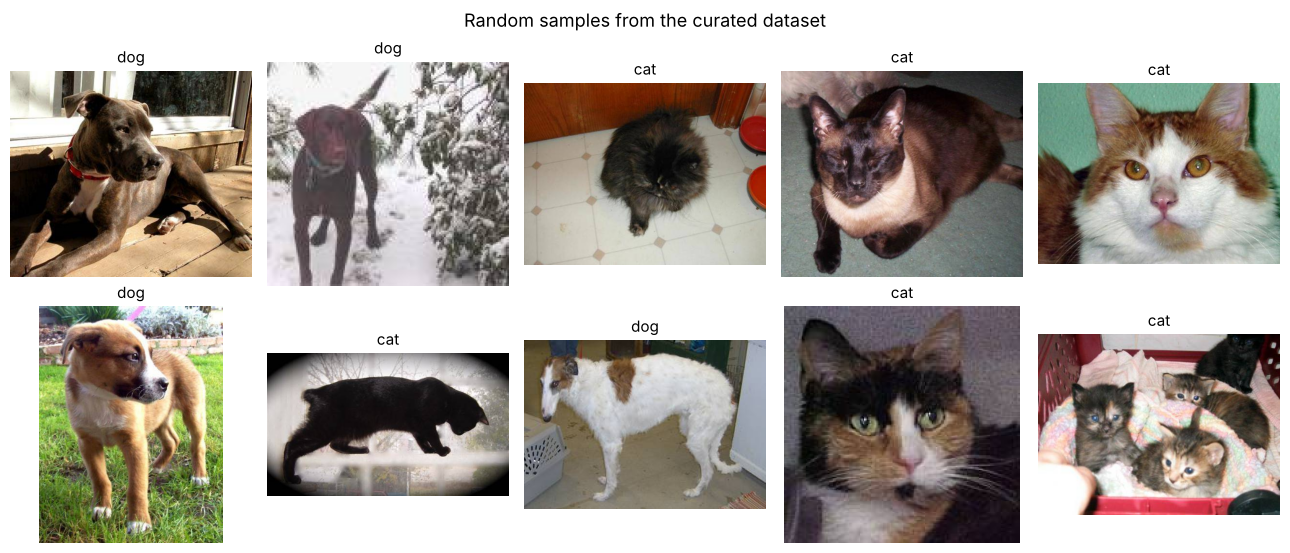

In [5]:
sample = labels_df.sample(10, random_state=1).reset_index(drop=True)
fig, axs = plt.subplots(2, 5, figsize=(13, 5.6))
for ax, (_, row) in zip(axs.flat, sample.iterrows()):
    ax.imshow(Image.open(os.path.join(DATA_DIR, row['filepath'])).convert('RGB'))
    ax.set_title(row['class_name'], fontsize=11)
    ax.axis('off')
plt.suptitle('Random samples from the curated dataset', fontsize=13)
plt.tight_layout()
plt.show()

<h4 style="font-family: Times New Roman"><strong>4. Custom PyTorch <tt>Dataset</tt> Class</strong></h4>

<p style="font-family:Times New Roman; text-align:justify; font-size:15px">
<tt>CatDogDataset</tt> reads <tt>labels.csv</tt> once, and then loads each image lazily inside
<tt>__getitem__</tt>, so only one batch of images is ever in memory. Three things are worth pointing out:
<ul style="font-family:Times New Roman; text-align:justify; font-size:15px">
  <li><tt>transform</tt> is a constructor argument instead of being hard-coded, because the five models do not
      all want the same preprocessing (see Section 6). The same dataset object can be wrapped with a different
      transform for each model.</li>
  <li><tt>.convert('RGB')</tt> guarantees three channels no matter how the JPEG was saved.</li>
  <li>The index is returned along with the image and label, so a wrong prediction can be traced back to its
      file for the error gallery at the end.</li>
</ul>
</p>

In [6]:
class CatDogDataset(Dataset):
    """Cats vs. dogs images listed in a CSV file (columns: filepath, label, class_name)."""

    def __init__(self, csv_file, root_dir, transform=None):
        self.df = pd.read_csv(csv_file)
        self.root_dir = root_dir
        self.transform = transform
        self.classes = CLASSES

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = Image.open(os.path.join(self.root_dir, row['filepath'])).convert('RGB')
        if self.transform is not None:
            image = self.transform(image)
        return image, int(row['label']), idx


raw_ds = CatDogDataset(os.path.join(DATA_DIR, 'labels.csv'), DATA_DIR)
img, lbl, i = raw_ds[0]
print('Number of images:', len(raw_ds))
print('First item     :', type(img).__name__, img.size, '| label =', lbl, f'({CLASSES[lbl]})')

Number of images: 1000
First item     : Image (499, 375) | label = 0 (cat)


<h4 style="font-family: Times New Roman"><strong>5. Loading the Pre-trained Models</strong></h4>

<p style="font-family:Times New Roman; text-align:justify; font-size:15px">
Each model is built from <tt>torchvision.models</tt> with its ImageNet-1k weights. <tt>MODEL_SPECS</tt> keeps
everything about a model in one place: the torchvision builder, the official weights enum, and a backup
weights file.
<br><br>
<b>A note on the weights.</b> torchvision downloads its weights from <tt>download.pytorch.org</tt>, and that
host is blocked in the environment this notebook was run in (the same kind of problem as the MNIST download in
Lab 6). So <tt>load_pretrained()</tt> first tries the normal torchvision call, and only if that fails it falls
back to ImageNet-1k weights for the <i>exact same architecture</i> hosted on GitHub by the <tt>timm</tt>
library. The architecture is still the torchvision one; only the numbers inside it come from a different
training run. Those state dicts use different parameter names (e.g. <tt>conv_stem</tt> instead of
<tt>features.0.0</tt>), so they are renamed before loading. <tt>load_state_dict</tt> is strict by default,
so a wrong mapping would raise an error instead of silently loading garbage. The printed <tt>source</tt>
column shows which weights each model actually used. On Colab or a normal PC the first branch succeeds and
the official torchvision weights are used, so the numbers may shift slightly from the ones shown here.
</p>

In [7]:
TIMM_GH = 'https://github.com/huggingface/pytorch-image-models/releases/download/'
IMAGENET_MEAN, IMAGENET_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)

MODEL_SPECS = {
    'ResNet-18': dict(builder=models.resnet18, weights=models.ResNet18_Weights.IMAGENET1K_V1,
                      mirror=TIMM_GH + 'v0.1-rsb-weights/resnet18_a1_0-d63eafa0.pth',
                      mirror_pre=dict(crop_pct=0.95, mean=IMAGENET_MEAN, std=IMAGENET_STD)),
    'ResNet-50': dict(builder=models.resnet50, weights=models.ResNet50_Weights.IMAGENET1K_V2,
                      mirror=TIMM_GH + 'v0.1-rsb-weights/resnet50_a1_0-14fe96d1.pth',
                      mirror_pre=dict(crop_pct=0.95, mean=IMAGENET_MEAN, std=IMAGENET_STD)),
    'MobileNetV2': dict(builder=models.mobilenet_v2, weights=models.MobileNet_V2_Weights.IMAGENET1K_V2,
                        mirror=TIMM_GH + 'v0.1-weights/mobilenetv2_100_ra-b33bc2c4.pth',
                        mirror_pre=dict(crop_pct=0.875, mean=IMAGENET_MEAN, std=IMAGENET_STD)),
    'EfficientNet-B0': dict(builder=models.efficientnet_b0, weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1,
                            mirror=TIMM_GH + 'v0.1-weights/efficientnet_b0_ra-3dd342df.pth',
                            mirror_pre=dict(crop_pct=0.875, mean=IMAGENET_MEAN, std=IMAGENET_STD)),
    'ViT-B/16': dict(builder=models.vit_b_16, weights=models.ViT_B_16_Weights.IMAGENET1K_V1,
                     mirror=TIMM_GH + 'v0.1-vitjx/jx_vit_base_p16_224-80ecf9dd.pth',
                     mirror_pre=dict(crop_pct=0.9, mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))),
}

In [8]:
def rename_by_order(src_sd, model):
    """Same architecture, different names: pair the tensors up in order and check every shape."""
    target = model.state_dict()
    assert len(src_sd) == len(target), 'parameter counts differ'
    new_sd = {}
    for (t_name, t_val), s_val in zip(target.items(), src_sd.values()):
        assert t_val.shape == s_val.shape, f'shape mismatch at {t_name}'
        new_sd[t_name] = s_val
    return new_sd


def rename_vit(src_sd, model):
    """timm stores ViT tensors alphabetically, so the ViT mapping is done by name instead."""
    new_sd = {'class_token': src_sd['cls_token'],
              'conv_proj.weight': src_sd['patch_embed.proj.weight'],
              'conv_proj.bias': src_sd['patch_embed.proj.bias'],
              'encoder.pos_embedding': src_sd['pos_embed'],
              'encoder.ln.weight': src_sd['norm.weight'], 'encoder.ln.bias': src_sd['norm.bias'],
              'heads.head.weight': src_sd['head.weight'], 'heads.head.bias': src_sd['head.bias']}
    names = {'norm1': 'ln_1', 'attn.proj': 'self_attention.out_proj', 'norm2': 'ln_2',
             'mlp.fc1': 'mlp.0', 'mlp.fc2': 'mlp.3'}
    for i in range(12):
        tv = f'encoder.layers.encoder_layer_{i}.'
        for p in ('weight', 'bias'):
            new_sd[tv + f'self_attention.in_proj_{p}'] = src_sd[f'blocks.{i}.attn.qkv.{p}']
            for timm_name, tv_name in names.items():
                new_sd[tv + f'{tv_name}.{p}'] = src_sd[f'blocks.{i}.{timm_name}.{p}']
    return new_sd


def mirror_transform(crop_pct, mean, std, size=224):
    return T.Compose([T.Resize(int(size / crop_pct), interpolation=T.InterpolationMode.BICUBIC),
                      T.CenterCrop(size), T.ToTensor(), T.Normalize(mean, std)])


def load_pretrained(name, weight_dir=os.path.join('data', 'weights')):
    spec = MODEL_SPECS[name]
    try:
        model = spec['builder'](weights=spec['weights'])
        transform = spec['weights'].transforms()
        source = f"torchvision {spec['weights']}"
    except Exception:
        os.makedirs(weight_dir, exist_ok=True)
        path = os.path.join(weight_dir, spec['mirror'].split('/')[-1])
        if not os.path.exists(path):
            urllib.request.urlretrieve(spec['mirror'], path)
        model = spec['builder'](weights=None)
        src_sd = torch.load(path, map_location='cpu')
        rename = rename_vit if name == 'ViT-B/16' else rename_by_order
        model.load_state_dict(rename(src_sd, model))
        transform = mirror_transform(**spec['mirror_pre'])
        source = 'timm ImageNet-1k (GitHub mirror)'
    return model.eval().to(device), transform, source


loaded = {}
for name in MODEL_SPECS:
    model, transform, source = load_pretrained(name)
    loaded[name] = (model, transform)
    n_params = sum(p.numel() for p in model.parameters())
    print(f"{name:16} {n_params / 1e6:6.1f} M params | weights: {source}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


ResNet-18          11.7 M params | weights: timm ImageNet-1k (GitHub mirror)


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


ResNet-50          25.6 M params | weights: timm ImageNet-1k (GitHub mirror)
Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


MobileNetV2         3.5 M params | weights: timm ImageNet-1k (GitHub mirror)
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


EfficientNet-B0     5.3 M params | weights: timm ImageNet-1k (GitHub mirror)


Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


ViT-B/16           86.6 M params | weights: timm ImageNet-1k (GitHub mirror)


<p style="font-family:Times New Roman; text-align:justify; font-size:15px">
The parameter counts already show a 25&times; spread: MobileNetV2 is the smallest at about 3.5&nbsp;M
parameters, while ViT-B/16 is the largest at about 86.6&nbsp;M.
</p>

<h4 style="font-family: Times New Roman"><strong>6. Preprocessing and <tt>DataLoader</tt> Objects</strong></h4>

<p style="font-family:Times New Roman; text-align:justify; font-size:15px">
A pre-trained model only works well if test images are prepared the same way as its training images. All
five expect a 224&times;224 RGB tensor, but they differ in <i>how</i> they get there: the resize size
before cropping (set by the crop percentage), the interpolation method, and the normalization statistics.
The ViT checkpoint, for example, was trained with pixels scaled to [-1, 1] (mean 0.5, std 0.5) rather than
the usual ImageNet mean/std. Feeding it the wrong normalization quietly costs accuracy. That is why each model
gets its <b>own</b> dataset + <tt>DataLoader</tt> pair built from its own transform.
<br><br>
<tt>shuffle=False</tt> keeps the image order identical across the five loaders, so predictions can be
compared image by image. Batch size 32 is a comfortable size for CPU inference.
</p>

In [9]:
BATCH_SIZE = 32
CSV_PATH = os.path.join(DATA_DIR, 'labels.csv')

loaders = {}
for name, (model, transform) in loaded.items():
    ds = CatDogDataset(CSV_PATH, DATA_DIR, transform=transform)
    loaders[name] = DataLoader(ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
    print(f"--- {name} ---")
    print(transform, '\n')

xb, yb, ib = next(iter(loaders['ResNet-18']))
print('One batch ->', 'images:', tuple(xb.shape), '| labels:', tuple(yb.shape), '| first labels:', yb[:8].tolist())

--- ResNet-18 ---
Compose(
    Resize(size=235, interpolation=bicubic, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    ToTensor()
    Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
) 

--- ResNet-50 ---
Compose(
    Resize(size=235, interpolation=bicubic, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    ToTensor()
    Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
) 

--- MobileNetV2 ---
Compose(
    Resize(size=256, interpolation=bicubic, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    ToTensor()
    Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
) 

--- EfficientNet-B0 ---
Compose(
    Resize(size=256, interpolation=bicubic, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    ToTensor()
    Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
) 

--- ViT-B/16 ---
Compose(
    Resize(size=248, interpolation=bicubic, max_size=None, antialias=True)
   

One batch -> images: (32, 3, 224, 224) | labels: (32,) | first labels: [0, 0, 0, 0, 0, 0, 0, 0]


<h4 style="font-family: Times New Roman"><strong>7. Model Inference</strong></h4>

<p style="font-family:Times New Roman; text-align:justify; font-size:15px">
Every model outputs 1,000 ImageNet logits per image. <tt>imagenet_to_catdog()</tt> takes the top-1 class and
maps it: indices 281&ndash;285 &rarr; <tt>cat</tt> (0), 151&ndash;268 &rarr; <tt>dog</tt> (1), anything else
&rarr; <tt>other</tt> (2). <tt>torch.no_grad()</tt> switches off gradient tracking because nothing is being
trained, which saves memory and time. The wall-clock time per image is also recorded (on this machine's CPU),
since speed is part of what makes a model suitable or not.
</p>

In [10]:
CAT_IDX = range(281, 286)
DOG_IDX = range(151, 269)
IMAGENET_NAMES = models.ResNet18_Weights.IMAGENET1K_V1.meta['categories']
print('Cat classes :', [IMAGENET_NAMES[i] for i in CAT_IDX])
print('Dog classes :', len(DOG_IDX), 'breeds, e.g.', [IMAGENET_NAMES[i] for i in (151, 207, 235, 268)])


def imagenet_to_catdog(top1):
    out = torch.full_like(top1, 2)
    out[(top1 >= 281) & (top1 <= 285)] = 0
    out[(top1 >= 151) & (top1 <= 268)] = 1
    return out


@torch.no_grad()
def run_inference(model, loader):
    y_true, y_pred, top1_all, conf_all = [], [], [], []
    start = time.time()
    for xb, yb, _ in loader:
        probs = model(xb.to(device)).softmax(dim=1).cpu()
        conf, top1 = probs.max(dim=1)
        y_true.append(yb)
        y_pred.append(imagenet_to_catdog(top1))
        top1_all.append(top1)
        conf_all.append(conf)
    elapsed = time.time() - start
    return (torch.cat(y_true).numpy(), torch.cat(y_pred).numpy(),
            torch.cat(top1_all).numpy(), torch.cat(conf_all).numpy(), elapsed)


results = {}
for name, (model, _) in loaded.items():
    y_true, y_pred, top1, conf, elapsed = run_inference(model, loaders[name])
    results[name] = dict(y_true=y_true, y_pred=y_pred, top1=top1, conf=conf, seconds=elapsed)
    print(f"{name:16} done in {elapsed:6.1f} s  ({elapsed / len(y_true) * 1000:5.1f} ms / image)")

Cat classes : ['tabby', 'tiger cat', 'Persian cat', 'Siamese cat', 'Egyptian cat']
Dog classes : 118 breeds, e.g. ['Chihuahua', 'golden retriever', 'German shepherd', 'Mexican hairless']


ResNet-18        done in   23.4 s  ( 23.4 ms / image)


ResNet-50        done in   56.6 s  ( 56.6 ms / image)


MobileNetV2      done in   16.3 s  ( 16.3 ms / image)


EfficientNet-B0  done in   22.5 s  ( 22.5 ms / image)


ViT-B/16         done in  166.2 s  (166.2 ms / image)


<h4 style="font-family: Times New Roman"><strong>8. Evaluation Metrics</strong></h4>

<p style="font-family:Times New Roman; text-align:justify; font-size:15px">
The four metrics answer slightly different questions:
<ul style="font-family:Times New Roman; text-align:justify; font-size:15px">
  <li><b>Accuracy</b> &mdash; out of all 1,000 images, how many got the right animal?</li>
  <li><b>Precision</b> &mdash; when the model says "cat", how often is it really a cat? (and the same for dog)</li>
  <li><b>Recall</b> &mdash; out of all real cats, how many did the model find? (and the same for dog)</li>
  <li><b>F1-score</b> &mdash; the harmonic mean of precision and recall, high only if both are high.</li>
</ul>
Precision, recall and F1 are <b>macro-averaged</b> over the two real classes (<tt>labels=[0, 1]</tt>), so cats
and dogs count equally. An <tt>other</tt> prediction cannot raise precision for any class but it lowers recall,
which is the right penalty for a model that looked at a cat and said "lynx". The "Other %" column shows how
often that happened.
</p>

In [11]:
rows = []
for name, r in results.items():
    model = loaded[name][0]
    prec, rec, f1, _ = precision_recall_fscore_support(r['y_true'], r['y_pred'], labels=[0, 1],
                                                       average='macro', zero_division=0)
    rows.append({'Model': name,
                 'Accuracy': accuracy_score(r['y_true'], r['y_pred']),
                 'Precision': prec, 'Recall': rec, 'F1-score': f1,
                 'Other %': (r['y_pred'] == 2).mean() * 100,
                 'Params (M)': sum(p.numel() for p in model.parameters()) / 1e6,
                 'ms / image': r['seconds'] / len(r['y_true']) * 1000})

metrics_df = pd.DataFrame(rows).set_index('Model').sort_values('F1-score', ascending=False)
metrics_df.style.format({'Accuracy': '{:.3f}', 'Precision': '{:.3f}', 'Recall': '{:.3f}', 'F1-score': '{:.3f}',
                         'Other %': '{:.1f}', 'Params (M)': '{:.1f}', 'ms / image': '{:.1f}'}) \
               .highlight_max(subset=['Accuracy', 'Precision', 'Recall', 'F1-score'], color='#cfe3f7')

,Accuracy,Precision,Recall,F1-score,Other %,Params (M),ms / image
Model,,,,,,,
ViT-B/16,0.937,0.991,0.937,0.963,5.4,86.6,166.2
ResNet-50,0.910,0.972,0.910,0.937,6.1,25.6,56.6
EfficientNet-B0,0.900,0.963,0.900,0.927,6.1,5.3,22.5
ResNet-18,0.883,0.956,0.883,0.913,7.0,11.7,23.4
MobileNetV2,0.888,0.947,0.888,0.911,5.4,3.5,16.3


<p style="font-family:Times New Roman; text-align:justify; font-size:15px">
Per-class breakdown for every model. The report is limited to the two real classes, and the number of <tt>other</tt> answers is printed underneath:
</p>

In [12]:
for name, r in results.items():
    print(f"=============== {name} ===============")
    print(classification_report(r['y_true'], r['y_pred'], labels=[0, 1],
                                target_names=['cat', 'dog'], digits=3, zero_division=0))
    for label, cls in enumerate(CLASSES):
        n_other = ((r['y_true'] == label) & (r['y_pred'] == 2)).sum()
        print(f"  real {cls}s predicted as 'other': {n_other}")
    print()

=============== ResNet-18 ===============
              precision    recall  f1-score   support

         cat      1.000     0.788     0.881       500
         dog      0.912     0.978     0.944       500

   micro avg      0.949     0.883     0.915      1000
   macro avg      0.956     0.883     0.913      1000
weighted avg      0.956     0.883     0.913      1000

  real cats predicted as 'other': 59
  real dogs predicted as 'other': 11

=============== ResNet-50 ===============
              precision    recall  f1-score   support

         cat      1.000     0.840     0.913       500
         dog      0.944     0.980     0.962       500

   micro avg      0.969     0.910     0.939      1000
   macro avg      0.972     0.910     0.937      1000
weighted avg      0.972     0.910     0.937      1000

  real cats predicted as 'other': 51
  real dogs predicted as 'other': 10

=============== MobileNetV2 ===============
              precision    recall  f1-score   support

         cat 

<h4 style="font-family: Times New Roman"><strong>9. Visual Comparison</strong></h4>

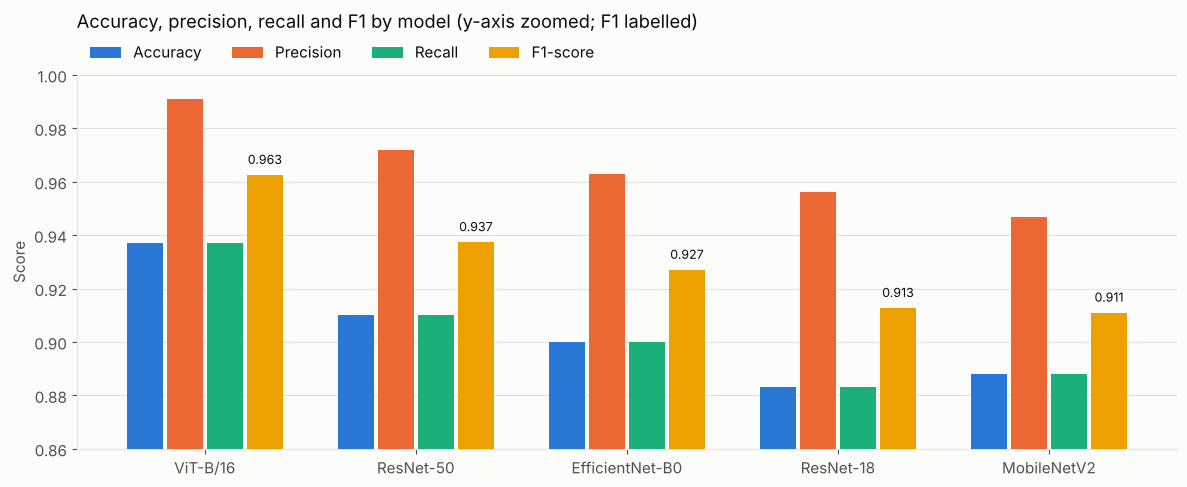

In [13]:
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']   # fixed categorical order
SURFACE, TEXT, MUTED, GRID = '#fcfcfb', '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'axes.edgecolor': GRID,
                     'axes.labelcolor': MUTED, 'xtick.color': MUTED, 'ytick.color': MUTED,
                     'text.color': TEXT, 'axes.spines.top': False, 'axes.spines.right': False,
                     'font.size': 11})

metric_cols = ['Accuracy', 'Precision', 'Recall', 'F1-score']
order = metrics_df.index.tolist()
x = np.arange(len(order))
bw = 0.19

fig, ax = plt.subplots(figsize=(12, 5))
for k, (m, color) in enumerate(zip(metric_cols, SERIES)):
    vals = metrics_df.loc[order, m].values
    ax.bar(x + (k - 1.5) * bw, vals, width=bw - 0.02, color=color, label=m, zorder=3)
for i, f1 in enumerate(metrics_df.loc[order, 'F1-score']):
    ax.text(i + 1.5 * bw, f1 + 0.003, f"{f1:.3f}", ha='center', va='bottom', fontsize=9, color=TEXT)
lo = metrics_df[metric_cols].values.min()
ax.set_ylim(np.floor((lo - 0.02) * 50) / 50, 1.0)
ax.set_xticks(x, order)
ax.set_ylabel('Score')
ax.yaxis.grid(True, color=GRID, zorder=0)
ax.set_title('Accuracy, precision, recall and F1 by model (y-axis zoomed; F1 labelled)', loc='left', pad=34)
ax.legend(ncol=4, frameon=False, loc='lower left', bbox_to_anchor=(0, 1.0))
plt.tight_layout()
plt.show()

<p style="font-family:Times New Roman; text-align:justify; font-size:15px">
The y-axis is zoomed in on purpose: all five models land between roughly 88% and 94% accuracy, and on a
0&ndash;1 axis the bars would look identical. The confusion matrices below show <i>where</i> each model's mistakes went, including the third
<tt>other</tt> column.
</p>

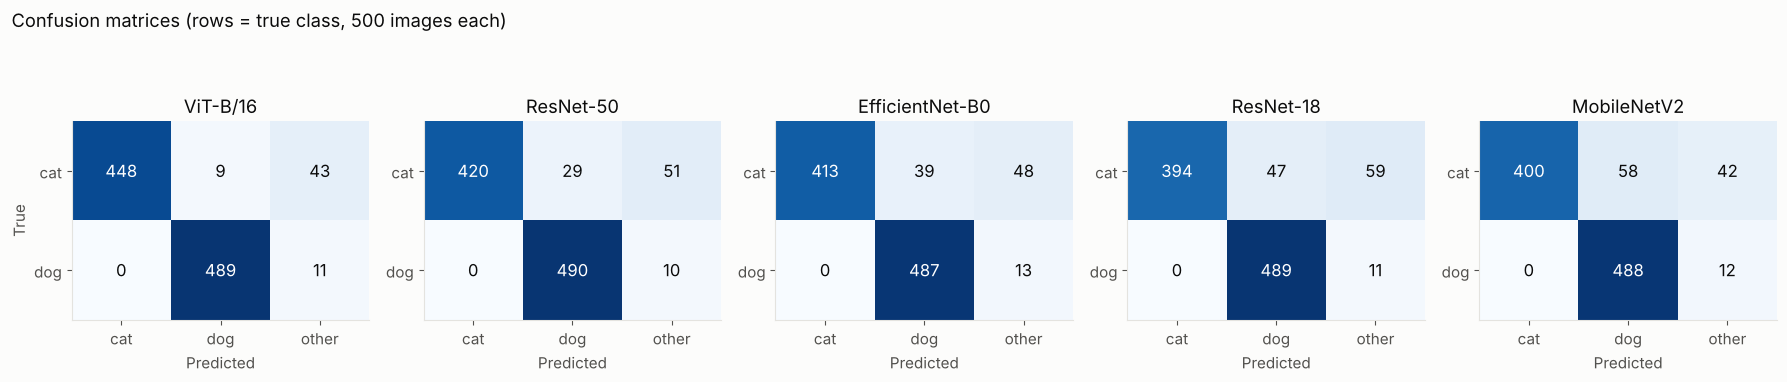

In [14]:
fig, axs = plt.subplots(1, 5, figsize=(18, 4))
for ax, name in zip(axs, order):
    r = results[name]
    cm = confusion_matrix(r['y_true'], r['y_pred'], labels=[0, 1, 2])[:2]
    ax.imshow(cm, cmap='Blues', vmin=0, vmax=N_PER_CLASS)
    for i in range(2):
        for j in range(3):
            ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=12,
                    color='white' if cm[i, j] > N_PER_CLASS / 2 else TEXT)
    ax.set_xticks([0, 1, 2], ['cat', 'dog', 'other'])
    ax.set_yticks([0, 1], ['cat', 'dog'])
    ax.set_xlabel('Predicted')
    ax.set_title(name)
axs[0].set_ylabel('True')
plt.suptitle('Confusion matrices (rows = true class, 500 images each)', x=0.01, ha='left')
plt.tight_layout()
plt.show()

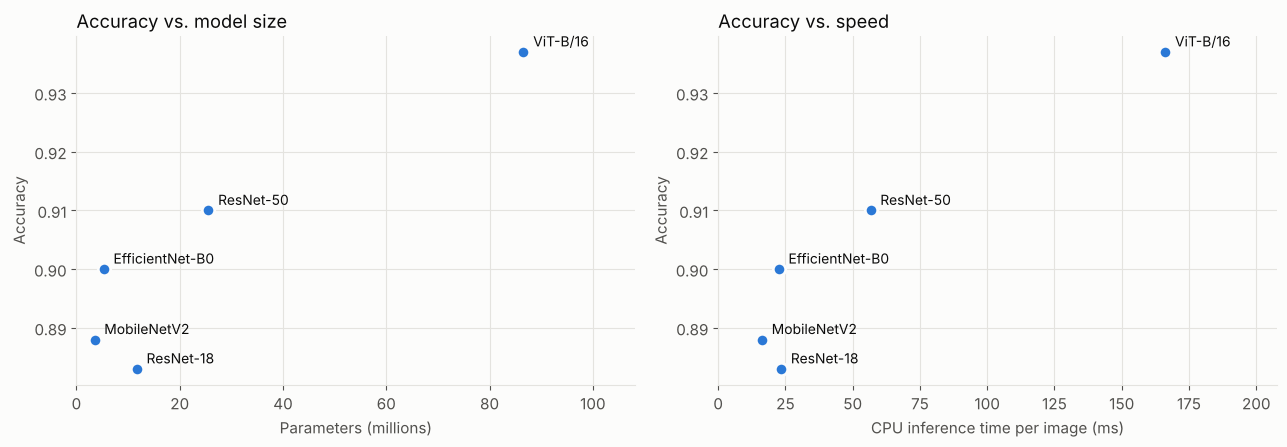

In [15]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, xcol, xlabel in [(axs[0], 'Params (M)', 'Parameters (millions)'),
                         (axs[1], 'ms / image', 'CPU inference time per image (ms)')]:
    ax.scatter(metrics_df[xcol], metrics_df['Accuracy'], s=80, color=SERIES[0],
               edgecolor=SURFACE, linewidth=2, zorder=3)
    for name, row in metrics_df.iterrows():
        ax.annotate(name, (row[xcol], row['Accuracy']), xytext=(7, 4), textcoords='offset points', fontsize=10)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Accuracy')
    ax.grid(True, color=GRID, zorder=0)
    ax.set_xlim(0, metrics_df[xcol].max() * 1.25)
axs[0].set_title('Accuracy vs. model size', loc='left')
axs[1].set_title('Accuracy vs. speed', loc='left')
plt.tight_layout()
plt.show()

<h4 style="font-family: Times New Roman"><strong>10. Where the Models Went Wrong</strong></h4>

<p style="font-family:Times New Roman; text-align:justify; font-size:15px">
Looking at the actual mistakes says more than another number. The first table lists the ImageNet classes the
models fell back on when they answered <tt>other</tt>. The gallery then shows the images that
<b>at least three of the five</b> models got wrong, captioned with every model's top-1 ImageNet guess.
</p>

In [16]:
other_counts = []
for name, r in results.items():
    mask = r['y_pred'] == 2
    for cls_idx in r['top1'][mask]:
        other_counts.append({'model': name, 'predicted ImageNet class': IMAGENET_NAMES[cls_idx]})
other_df = pd.DataFrame(other_counts)
(other_df.groupby('predicted ImageNet class').size().sort_values(ascending=False)
         .head(12).rename('times predicted (all models)').to_frame())

,times predicted (all models)
predicted ImageNet class,
lynx,28
Angora,23
dingo,12
white wolf,12
mink,10
bucket,8
bath towel,7
plastic bag,7
dishwasher,7


Images missed by 0..5 models: [779, 103, 41, 28, 32, 17]


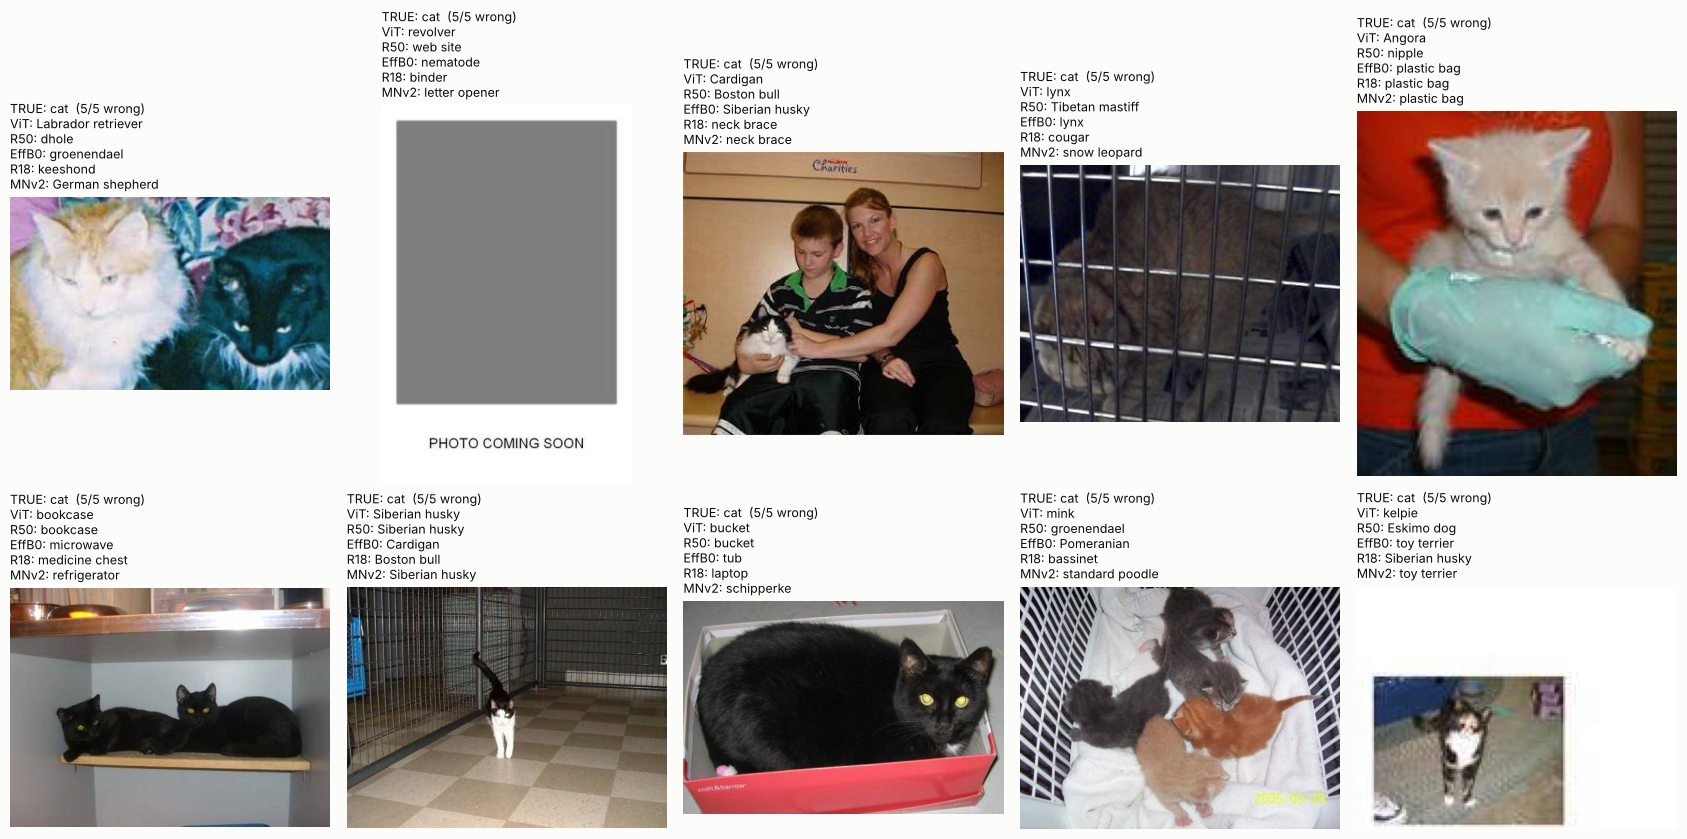

In [17]:
wrong = np.stack([results[n]['y_pred'] != results[n]['y_true'] for n in order])
n_wrong = wrong.sum(axis=0)
print('Images missed by 0..5 models:', np.bincount(n_wrong, minlength=6).tolist())

hard = np.where(n_wrong >= 3)[0]
hard = hard[np.argsort(-n_wrong[hard])][:10]
short = {'ResNet-18': 'R18', 'ResNet-50': 'R50', 'MobileNetV2': 'MNv2', 'EfficientNet-B0': 'EffB0', 'ViT-B/16': 'ViT'}

if len(hard):
    cols = 5
    rows_n = int(np.ceil(len(hard) / cols))
    fig, axs = plt.subplots(rows_n, cols, figsize=(17, 4.6 * rows_n))
    for ax in np.atleast_1d(axs).flat:
        ax.axis('off')
    for ax, idx in zip(np.atleast_1d(axs).flat, hard):
        row = labels_df.iloc[idx]
        ax.imshow(Image.open(os.path.join(DATA_DIR, row['filepath'])).convert('RGB'))
        guesses = '\n'.join(f"{short[n]}: {IMAGENET_NAMES[results[n]['top1'][idx]][:18]}" for n in order)
        ax.set_title(f"TRUE: {row['class_name']}  ({n_wrong[idx]}/5 wrong)\n{guesses}", fontsize=9, loc='left')
    plt.tight_layout()
    plt.show()

<h4 style="font-family: Times New Roman"><strong>11. Analysis</strong></h4>

<p style="font-family:Times New Roman; text-align:justify; font-size:15px">
<b>Overall ranking.</b> By F1-score the order is <b>ViT-B/16</b> (0.963) &gt; <b>ResNet-50</b> (0.937) &gt;
<b>EfficientNet-B0</b> (0.927) &gt; <b>ResNet-18</b> (0.913) &asymp; <b>MobileNetV2</b> (0.911). Accuracy gives
the same order except that MobileNetV2 (0.888) edges out ResNet-18 (0.883). The gap between best and worst is
about 5 accuracy points, which is 54 more correctly classified images out of 1,000. No model was fine-tuned, so
every difference here comes from what the models already learned on ImageNet.
</p>

<p style="font-family:Times New Roman; text-align:justify; font-size:15px">
<b>Every model finds dogs much more easily than cats.</b> Dog recall is about 97&ndash;98% for all five models,
but cat recall ranges from 79% (ResNet-18) to 90% (ViT). The confusion matrices show the mistakes only go one
way: <i>no model ever called a dog a cat</i>, while 9&ndash;58 cats were called dogs and 42&ndash;59 more were
called something else. A big part of the reason is ImageNet itself. It has 118 dog classes but only 5 cat
classes, so the models spent far more of their training on dog features and have far more "dog" outputs to
land on. A blurry, dark, or partly hidden cat only has to look a little like one of 118 breeds to get pulled
into the dog group. This is also why <b>precision looks so high</b> (0.95&ndash;0.99): "cat" precision is a
perfect 1.000 for every model, and "other" answers never count against precision. Recall and accuracy are the
more honest numbers for this dataset.
</p>

<p style="font-family:Times New Roman; text-align:justify; font-size:15px">
<b>The "other" answers are near misses, not random noise.</b> The most common ones were <i>lynx</i> and
<i>Angora</i> (an Angora rabbit &mdash; a fluffy white kitten looks like one), followed by wolf/dingo-type
classes and household objects such as <i>bucket</i>, <i>bath towel</i>, <i>plastic bag</i> and
<i>dishwasher</i>. In those photos the cat is small or half-hidden and the object fills most of the frame,
so the model honestly reports the biggest thing it sees. ImageNet labels each image with one main object, and
these models carry that habit over.
</p>

<p style="font-family:Times New Roman; text-align:justify; font-size:15px">
<b>Some mistakes come from the data, not the model.</b> 779 of the 1,000 images were classified correctly by
all five models, and only 17 fooled every one of them. The error gallery shows why most of those 17 are
hard: several cats in one photo, a cat being held by people, a black cat in a dark room, a cat behind a cage,
or a tiny cat in a low-resolution photo. One "cat" image is actually a grey <b>"PHOTO COMING SOON"</b>
placeholder &mdash; a labelling error in the original Kaggle data that passed every automatic curation check
(it opens fine, is big enough, and is not a duplicate). Only looking at the errors revealed it. A real
project would remove it and do a manual review pass, but it is left in here so the reported numbers match what
the pipeline actually produced.
</p>

<p style="font-family:Times New Roman; text-align:justify; font-size:15px">
<b>Why the models differ &mdash; architecture and complexity.</b>
<ul style="font-family:Times New Roman; text-align:justify; font-size:15px">
  <li><b>ViT-B/16</b> splits the image into 196 patches of 16&times;16 pixels and uses self-attention, so every
      patch can look at every other patch from the very first layer. A CNN only sees a small neighbourhood per
      layer and builds up a global view slowly. Global context helps exactly in the hard cases above: a cat that
      fills only part of the frame, or is partly covered, can still be linked to its ears, eyes and tail
      elsewhere in the image. It is also the largest model (86.6&nbsp;M parameters) and these weights were
      pre-trained on ImageNet-21k (about 14 million images) before being fine-tuned on ImageNet-1k, so it has
      seen far more animals than the CNNs. Transformers have weaker built-in assumptions about images than CNNs,
      and they need that much data to pay off.</li>
  <li><b>ResNet-50 vs. ResNet-18</b> is the cleanest comparison because both use the same design and the same
      training recipe; the only real difference is depth (50 vs. 18 layers) and bottleneck blocks. The deeper
      network gets +2.7 points of accuracy and fewer cat&rarr;dog mistakes (29 vs. 47), because it has more
      capacity to learn fine-grained features such as face shape and fur texture.</li>
  <li><b>EfficientNet-B0</b> beats ResNet-18 with less than half the parameters (5.3&nbsp;M vs. 11.7&nbsp;M).
      Its depth, width and input resolution were balanced together (compound scaling), and its MBConv blocks
      use cheap depthwise convolutions plus squeeze-and-excitation, which lets the network re-weight channels
      based on what is in the whole image &mdash; a small step toward the global context that ViT has.</li>
  <li><b>MobileNetV2</b> is the smallest (3.5&nbsp;M) and fastest model. Its inverted-residual blocks are built
      for phones, trading some capacity for speed. It still matches ResNet-18 on accuracy, but it has the most
      cat&rarr;dog confusions (58), which suggests its smaller feature set does not separate the two animals
      as clearly.</li>
</ul>
</p>

<p style="font-family:Times New Roman; text-align:justify; font-size:15px">
<b>Input requirements.</b> All five take a 224&times;224 RGB image, but their preprocessing differs, and
Section 6 printed each pipeline. The ResNets resize to 235 before cropping, the mobile models to 256, ViT to 248,
and ViT normalizes with mean/std 0.5 instead of the usual ImageNet statistics. Giving each model its own
transform is part of why the comparison is fair. Center-cropping also has a cost on this dataset: many photos are
wide, and a cat sitting near the edge can be partly cut off before the model ever sees it. ViT is also locked to
its 16-pixel patch grid and learned position embeddings, so running it at a different resolution would need
those embeddings to be interpolated, while the CNNs would accept other sizes directly.
</p>

<p style="font-family:Times New Roman; text-align:justify; font-size:15px">
<b>Cost and suitability.</b> The accuracy-vs-speed plot shows a clear trade-off. ViT is about 7&ndash;10&times;
slower per image than MobileNetV2 or EfficientNet-B0 on CPU for about 4&ndash;5 extra points of accuracy over MobileNetV2 (3.7 over EfficientNet-B0).
ResNet-50 sits in the middle. For offline batch labelling of a photo collection, ViT-B/16 is the best choice.
For a phone app or anything real-time, <b>EfficientNet-B0</b> is the sweet spot: almost ResNet-50 accuracy at
ResNet-18 speed and a fifth of ResNet-50's size.
</p>

<p style="font-family:Times New Roman; text-align:justify; font-size:15px">
<i>A caveat on the weights:</i> as explained in Section 5, this run used timm's ImageNet-1k weights inside the
torchvision architectures, because torchvision's download server was not reachable. Those weights come from
different training recipes than torchvision's own (the ResNets in particular use the stronger
"ResNet strikes back" recipe). Re-running the notebook with the official weights should give the same overall
picture, but the exact numbers, and possibly the order of the close pairs such as ResNet-18 vs. MobileNetV2, may
change.
</p>

<h4 style="font-family: Times New Roman"><strong>12. Conclusion</strong></h4>

<p style="font-family:Times New Roman; text-align:justify; font-size:15px">
Five ImageNet-pretrained models from <tt>torchvision.models</tt> were evaluated, with no fine-tuning, on a
curated and balanced set of 1,000 cat and dog photos, loaded through a custom <tt>Dataset</tt> class and
per-model <tt>DataLoader</tt>s. <b>ViT-B/16 performed best</b> (93.7% accuracy, 0.963 macro F1), thanks to
global self-attention, the most parameters, and the largest pre-training dataset, but it was also by far the
slowest. <b>ResNet-50</b> and <b>EfficientNet-B0</b> followed, and EfficientNet-B0 gave the best balance of
accuracy, size and speed. The smaller <b>ResNet-18</b> and <b>MobileNetV2</b> trailed by a few points.
<br><br>
The more interesting finding is that every model shared the same weakness: cats were missed far more often
than dogs, mostly being pulled toward the 118 dog classes or toward objects in the scene. That bias comes from
the ImageNet label set, not from any one architecture, so picking a bigger model reduces the problem but does not
remove it. The natural next step would be to fine-tune the final layer of each model on a two-class cat/dog
head, which should close most of that gap, and to manually clean the remaining label noise such as the
placeholder image found during error analysis.
</p>